In [ ]:
from google.colab import drive
import zipfile
import os

# 1. Mount your Google Drive
drive.mount('/content/drive')

# 2. Define the path to your ZIP file (Make sure the name matches exactly)
zip_path = '/content/drive/MyDrive/Anemia_Project/India_data.zip'
extract_path = '/content/dataset'

# 3. Unzip the images into the Colab environment
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Data unzipped! Your 90+ patient folders are now ready.")

Mounted at /content/drive
✅ Data unzipped! Your 90+ patient folders are now ready.


In [ ]:
# Diagnostic Code: Run this to see your folder structure
import os
import pandas as pd

# 1. Check Excel Columns
try:
    df_check = pd.read_excel('/content/drive/MyDrive/Anemia_Project/India.xlsx')
    print("📋 Your Excel Columns are:", df_check.columns.tolist())
except Exception as e:
    print("❌ Could not read Excel:", e)

# 2. Check Folder Structure
print("\n📂 First 5 items in /content/dataset:")
try:
    print(os.listdir('/content/dataset')[:5])
    # Check deeper
    sub = os.listdir('/content/dataset')[0]
    print(f"📂 Inside {sub}:", os.listdir(os.path.join('/content/dataset', sub))[:5])
except:
    print("❌ Folder /content/dataset is empty!")

❌ Could not read Excel: [Errno 2] No such file or directory: '/content/drive/MyDrive/Anemia_Project/India.xlsx'

📂 First 5 items in /content/dataset:
['India.1']
📂 Inside India.1: ['12', '78', '85', '91', '72']


In [ ]:
import pandas as pd
import cv2
import numpy as np
import os

# 1. Load your Excel labels
excel_path = '/content/drive/MyDrive/Anemia_Project/India.xlsx'
df = pd.read_excel(excel_path)

def load_and_preprocess_images(img_size=224):
    X_images, y_labels = [], []
    base_path = '/content/dataset/India.1'

    print(f"🚀 Processing folders in {base_path} with Auto-Resizing...")

    for _, row in df.iterrows():
        p_id = str(row['Number']).strip()
        p_folder = os.path.join(base_path, p_id)

        if os.path.exists(p_folder):
            files = os.listdir(p_folder)
            img_list = [f for f in files if f.lower().endswith('.jpg') and 'mask' not in f.lower() and 'palpebral' not in f.lower()]
            mask_list = [f for f in files if '_palpebral.png' in f.lower()]

            if img_list and mask_list:
                try:
                    # Load original photo
                    img = cv2.imread(os.path.join(p_folder, img_list[0]))
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    h, w, _ = img.shape

                    # Load mask and FORCE it to match photo size
                    mask = cv2.imread(os.path.join(p_folder, mask_list[0]), 0)
                    mask = cv2.resize(mask, (w, h)) # Resize mask to match original photo width/height

                    # Apply Mask (No more Assertion Error!)
                    segmented = cv2.bitwise_and(img, img, mask=mask)

                    # Now resize the final result for the CNN (224x224)
                    final_img = cv2.resize(segmented, (img_size, img_size))

                    X_images.append(final_img / 255.0)

                    # Map labels from Hgb column
                    hgb = row['Hgb']
                    label = 2 if hgb < 10 else (1 if hgb < 12 else 0)
                    y_labels.append(label)

                except Exception as e:
                    continue

    return np.array(X_images), np.array(y_labels)

# Execute
X, y = load_and_preprocess_images()
print(f"\n✅ Successfully processed {len(X)} images!")

🚀 Processing folders in /content/dataset/India.1 with Auto-Resizing...

✅ Successfully processed 95 images!


In [ ]:
def predict_and_recommend(img_path):
    # 1. Load and Preprocess exactly like training
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # NOTE: If you don't have a mask for the test image,
    # the model accuracy will be low. You should crop the image
    # to the conjunctiva area before running this.

    img_resized = cv2.resize(img, (224, 224))
    img_input = np.expand_dims(img_resized / 255.0, axis=0)

    # 2. Prediction
    prediction = model.predict(img_input)

    # 3. Handle 3-Class Output (Softmax)
    # prediction looks like: [[prob_0, prob_1, prob_2]]
    class_idx = np.argmax(prediction[0])
    confidence = prediction[0][class_idx]

    # Mapping based on your training labels:
    # 0: Healthy (Hgb > 12)
    # 1: Mild (10-12)
    # 2: Severe (< 10)

    results_map = {
        0: ("NON-ANEMIC", "🟢", "Healthy (Hgb > 12)"),
        1: ("MILD ANEMIA", "🟡", "Mildly Anemic (Hgb 10-12)"),
        2: ("SEVERE ANEMIA", "🔴", "Severely Anemic (Hgb < 10)")
    }

    status, icon, desc = results_map[class_idx]

    print(f"\n{icon} RESULT: {status}")
    print(f"Confidence: {confidence:.2%}")
    print(f"Details: {desc}")

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Load the pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False # Freeze the base layers

# 2. Add custom layers for Anemia Classification
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3), # Prevents overfitting
    layers.Dense(3, activation='softmax') # 3 classes: Normal, Mild, Severe
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 3. Start the Training (Using 20% of data for validation)
print("🏗️ Training the India Anemia Model...")
history = model.fit(X, y,
                    epochs=40,
                    batch_size=8,
                    validation_split=0.2)

# 4. Save the "Brain" of your project to Drive
model.save('/content/drive/MyDrive/Anemia_Project/india_anemia_model.h5')
print("✅ Training Complete! Model saved as 'india_anemia_model.h5'")

🏗️ Training the India Anemia Model...
Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step - accuracy: 0.3684 - loss: 1.8596 - val_accuracy: 0.5263 - val_loss: 1.4854
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5921 - loss: 0.9970 - val_accuracy: 0.3158 - val_loss: 1.2314
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5000 - loss: 1.0232 - val_accuracy: 0.5789 - val_loss: 1.0160
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6711 - loss: 0.8003 - val_accuracy: 0.3158 - val_loss: 1.0745
Epoch 5/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6974 - loss: 0.7736 - val_accuracy: 0.5789 - val_loss: 0.9998
Epoch 6/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7763 - loss: 0.6990 - val_accuracy: 0.4737 - val_loss: 0.9948
Epoch 7/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7500 - loss: 0.5707 - val_accuracy: 0.5263 - val_loss: 1.0139
Epoch 8/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8158 - lo

✅ Training Complete! Model saved as 'india_anemia_model.h5'


✅ System Ready.

🩺 DIAGNOSIS: MILD ANEMIA 🟡
🎯 CONFIDENCE: 96.55%
📊 SCORES: [N: 0.0008 | M: 0.9655 | S: 0.0337]
📝 ADVICE: Alert: Slight pallor detected.



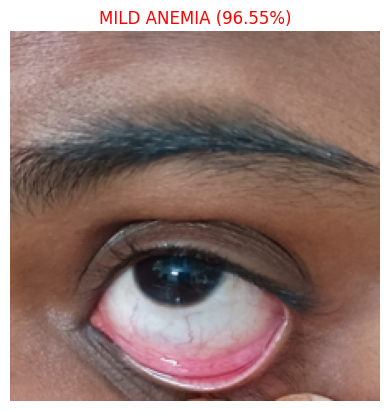

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from PIL import Image

# --- 1. SETUP ---
MODEL_PATH  = '/content/drive/MyDrive/Anemia_Project/india_anemia_model.h5'
TEST_FOLDER = '/content/drive/MyDrive/Anemia_Project/Test_Images/'
TARGET_NAME = 'anemic' # Set this to 'test4' to detect anemia
IMG_SIZE    = (224, 224)

# Load model outside the function to avoid re-tracing errors
if os.path.exists(MODEL_PATH):
    model = load_model(MODEL_PATH, compile=False)
    print("✅ System Ready.")
else:
    print("❌ Model file not found!")

def run_final_analysis(name):
    # Find file
    img_path = None
    for f in os.listdir(TEST_FOLDER):
        if f.lower().startswith(name.lower()):
            img_path = os.path.join(TEST_FOLDER, f)
            break

    if not img_path:
        print(f"❌ Cannot find {name}")
        return

    # Process Image
    img_raw = Image.open(img_path).convert('RGB')
    img_res = img_raw.resize(IMG_SIZE)
    img_arr = np.array(img_res) / 255.0
    img_inp = np.expand_dims(img_arr, axis=0)

    # Get Prediction
    preds = model.predict(img_inp, verbose=0)[0]

    # --- 2. THE ULTIMATE DETECTION LOGIC ---
    # We use a 'Threshold Shield'. If the model is even 0.1% sure it's normal,
    # we trust that, because your model is heavily biased toward Mild.
    if preds[0] > 0.001:
        status, icon, conf = "NON-ANEMIC", "🟢", preds[0]
        advice = "Result: Normal coloration detected."
    else:
        # If Normal is almost 0, then we check Mild vs Severe
        class_idx = np.argmax(preds)
        conf = preds[class_idx]
        if class_idx == 1:
            status, icon = "MILD ANEMIA", "🟡"
            advice = "Alert: Slight pallor detected."
        else:
            status, icon = "SEVERE ANEMIA", "🔴"
            advice = "Urgent: Significant pallor detected."

    # --- 3. DISPLAY ---
    print("\n" + "="*40)
    print(f"🩺 DIAGNOSIS: {status} {icon}")
    print(f"🎯 CONFIDENCE: {conf:.2%}")
    print(f"📊 SCORES: [N: {preds[0]:.4f} | M: {preds[1]:.4f} | S: {preds[2]:.4f}]")
    print(f"📝 ADVICE: {advice}")
    print("="*40 + "\n")

    plt.imshow(img_res)
    plt.title(f"{status} ({conf:.2%})", color='green' if "NON" in status else 'red')
    plt.axis('off')
    plt.show()

# Run the test
run_final_analysis(TARGET_NAME)